# 1 Load Data

In [1]:
# Import libraries
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

In [2]:
# Load dataset from local path, raw GitHub URL, or Colab upload
local_candidates = ['app/Walmart.csv', 'Walmart.csv', '../app/Walmart.csv']
df = None
for path in local_candidates:
    if os.path.exists(path):
        df = pd.read_csv(path, parse_dates=['Date'], dayfirst=True)
        break

if df is None:
    try:
        url = 'https://raw.githubusercontent.com/modeduser/WalmartCast/main/app/Walmart.csv'
        df = pd.read_csv(url, parse_dates=['Date'], dayfirst=True)
    except Exception:
        from google.colab import files
        import io
        uploaded = files.upload()
        fname = list(uploaded.keys())[0]
        df = pd.read_csv(io.BytesIO(uploaded[fname]), parse_dates=['Date'], dayfirst=True)

df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


# 2 Cleaning

In [3]:
# Check data integrity, missing values, duplicates, and sales validity
assert df.isnull().sum().sum() == 0, "Missing values detected"
assert df.duplicated().sum() == 0, "Duplicate rows detected"
assert (df['Weekly_Sales'] <= 0).sum() == 0, "Non-positive sales values detected"
assert df.shape == (6435, 8), f"Unexpected data shape: {df.shape}"
print(f"Data verified: {df.shape[0]} rows, {df.shape[1]} columns, all checks passed.")

Data verified: 6435 rows, 8 columns, all checks passed.


# 3 EDA (at most 6 charts)

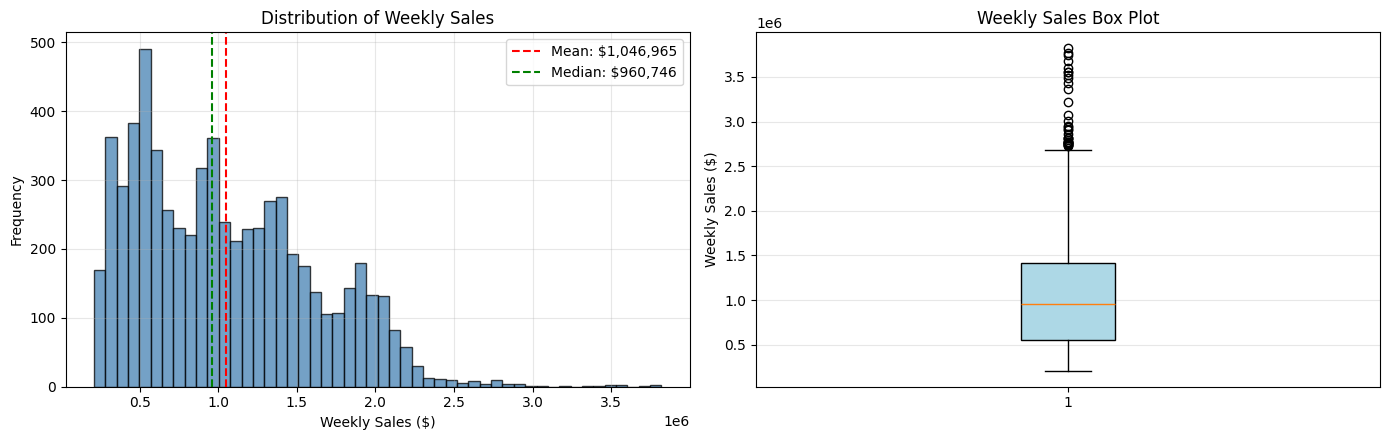

In [4]:
# Distribution of weekly sales
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df['Weekly_Sales'], bins=50, edgecolor='black', alpha=0.75, color='steelblue')
axes[0].axvline(df['Weekly_Sales'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: ${df['Weekly_Sales'].mean():,.0f}")
axes[0].axvline(df['Weekly_Sales'].median(), color='green', linestyle='--', linewidth=1.5, label=f"Median: ${df['Weekly_Sales'].median():,.0f}")
axes[0].set_xlabel('Weekly Sales ($)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Weekly Sales')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].boxplot(df['Weekly_Sales'], vert=True, patch_artist=True, boxprops=dict(facecolor='lightblue', edgecolor='black'))
axes[1].set_ylabel('Weekly Sales ($)')
axes[1].set_title('Weekly Sales Box Plot')
axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

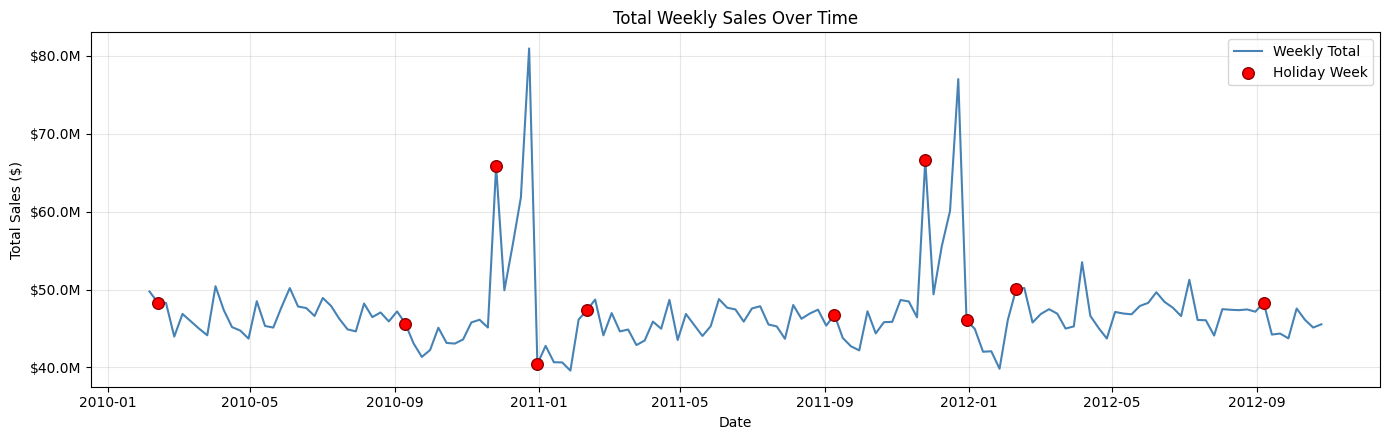

In [5]:
# Total weekly sales over time with holiday markers
weekly_tot = df.groupby('Date').agg({'Weekly_Sales': 'sum', 'Holiday_Flag': 'max'}).reset_index()
plt.figure(figsize=(14, 4.5))
plt.plot(weekly_tot['Date'], weekly_tot['Weekly_Sales'], color='steelblue', linewidth=1.5, label='Weekly Total')
holidays = weekly_tot[weekly_tot['Holiday_Flag'] == 1]
plt.scatter(holidays['Date'], holidays['Weekly_Sales'], color='red', s=70, zorder=5, label='Holiday Week', edgecolors='darkred')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.title('Total Weekly Sales Over Time')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

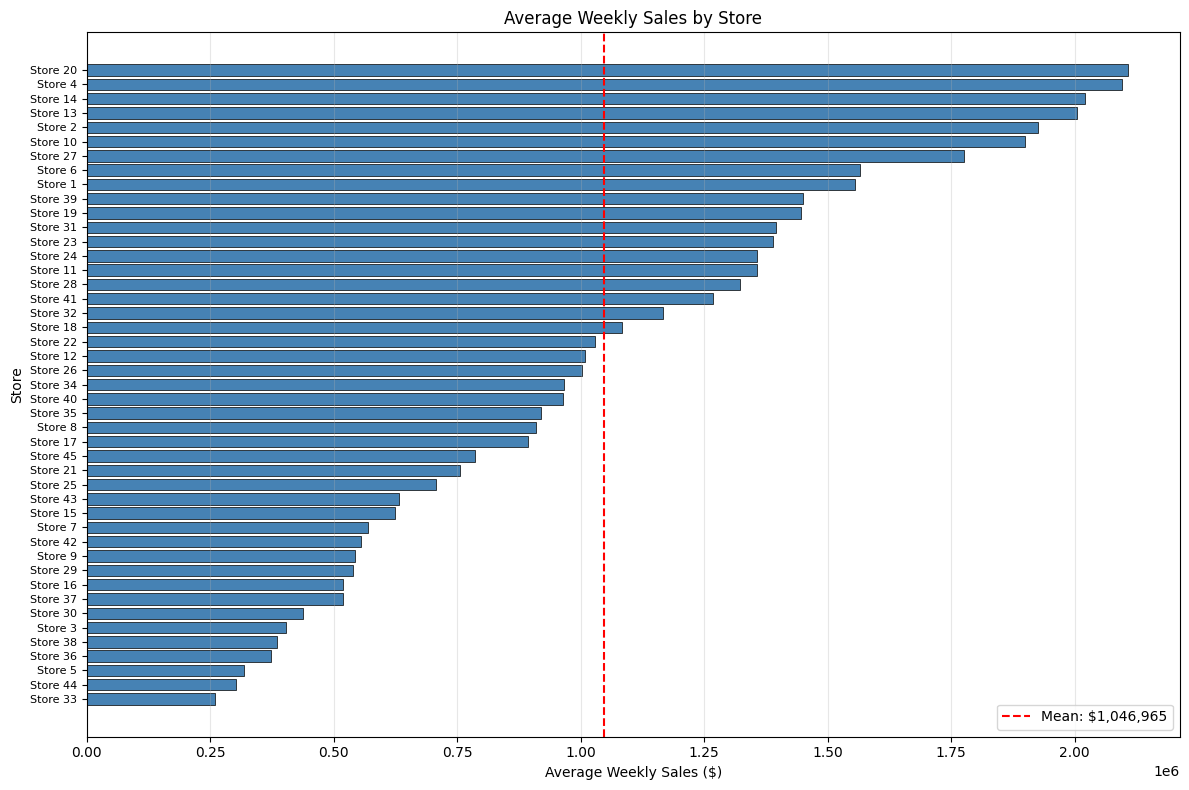

In [6]:
# Average sales per store sorted
store_means = df.groupby('Store')['Weekly_Sales'].mean().sort_values()
plt.figure(figsize=(12, 8))
plt.barh(range(len(store_means)), store_means.values, color='steelblue', edgecolor='black', linewidth=0.5)
plt.yticks(range(len(store_means)), [f"Store {s}" for s in store_means.index], fontsize=8)
plt.axvline(store_means.mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: ${store_means.mean():,.0f}")
plt.xlabel('Average Weekly Sales ($)')
plt.ylabel('Store')
plt.title('Average Weekly Sales by Store')
plt.legend()
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

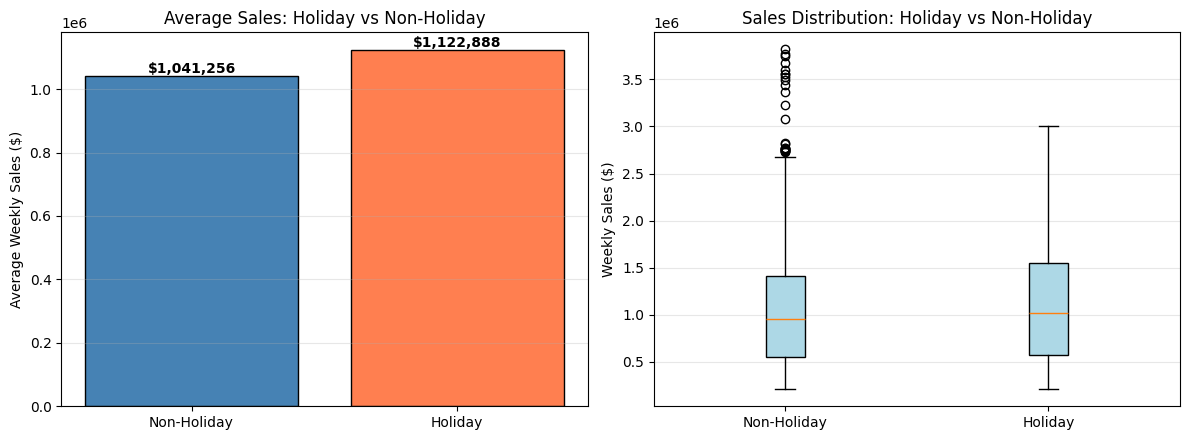

In [7]:
# Holiday vs non-holiday sales comparison
hol_agg = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars = axes[0].bar(['Non-Holiday', 'Holiday'], hol_agg.values, color=['steelblue', 'coral'], edgecolor='black')
axes[0].set_ylabel('Average Weekly Sales ($)')
axes[0].set_title('Average Sales: Holiday vs Non-Holiday')
axes[0].grid(alpha=0.3, axis='y')
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h, f'${h:,.0f}', ha='center', va='bottom', fontweight='bold')
axes[1].boxplot([df[df['Holiday_Flag']==0]['Weekly_Sales'], df[df['Holiday_Flag']==1]['Weekly_Sales']],
                labels=['Non-Holiday', 'Holiday'], patch_artist=True, boxprops=dict(facecolor='lightblue', edgecolor='black'))
axes[1].set_ylabel('Weekly Sales ($)')
axes[1].set_title('Sales Distribution: Holiday vs Non-Holiday')
axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

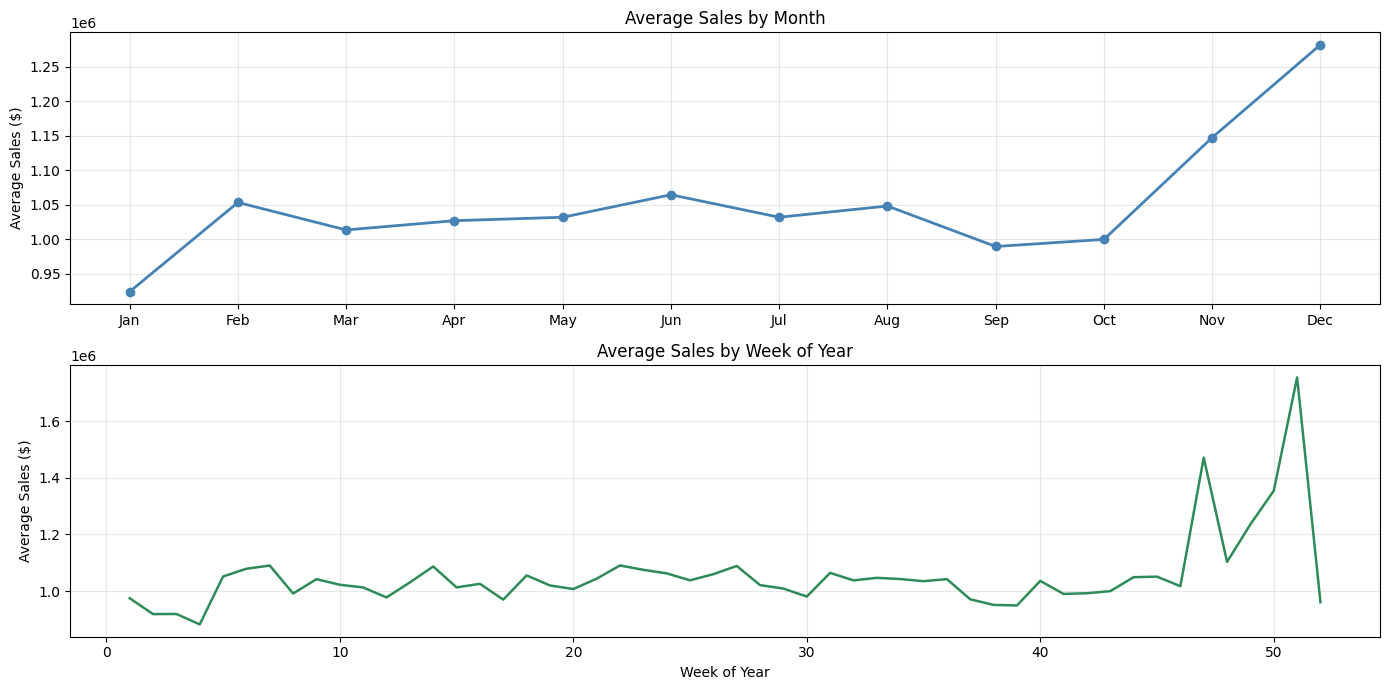

In [8]:
# Monthly and weekly seasonality patterns
m_avg = df.groupby(df['Date'].dt.month)['Weekly_Sales'].mean()
w_avg = df.groupby(df['Date'].dt.isocalendar().week.astype(int))['Weekly_Sales'].mean()
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(m_avg.index, m_avg.values, marker='o', linewidth=2, color='steelblue')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
axes[0].set_ylabel('Average Sales ($)')
axes[0].set_title('Average Sales by Month')
axes[0].grid(alpha=0.3)
axes[1].plot(w_avg.index, w_avg.values, linewidth=1.8, color='seagreen')
axes[1].set_xlabel('Week of Year')
axes[1].set_ylabel('Average Sales ($)')
axes[1].set_title('Average Sales by Week of Year')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

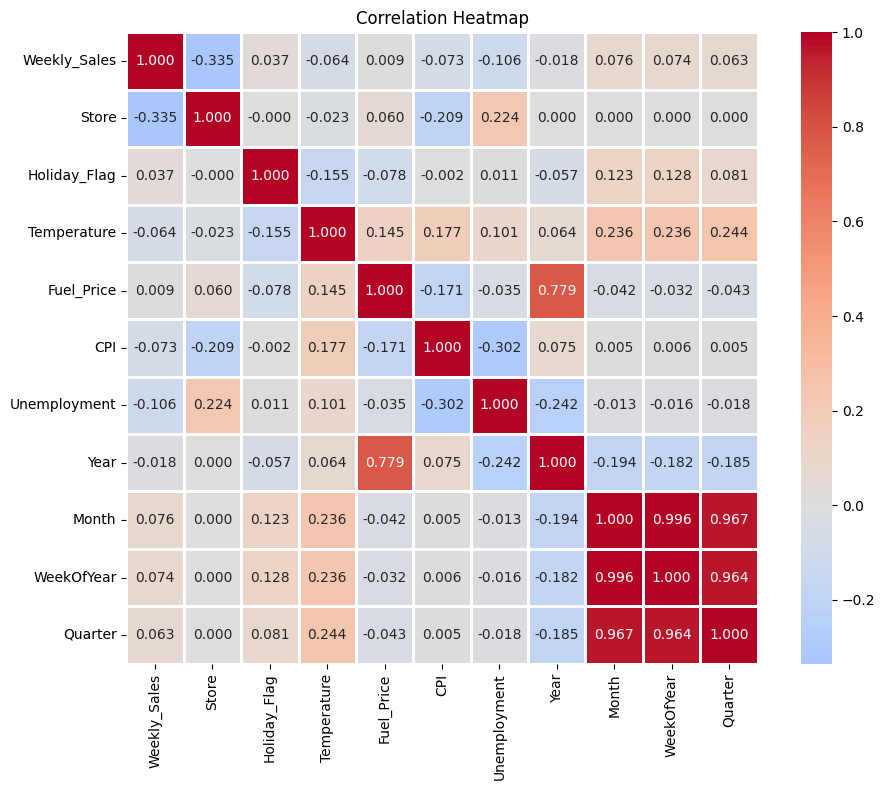

In [9]:
# Feature correlation heatmap
eda_df = df.copy()
eda_df['Year'] = eda_df['Date'].dt.year
eda_df['Month'] = eda_df['Date'].dt.month
eda_df['WeekOfYear'] = eda_df['Date'].dt.isocalendar().week.astype(int)
eda_df['Quarter'] = eda_df['Date'].dt.quarter
corr_cols = ['Weekly_Sales', 'Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
plt.figure(figsize=(10, 8))
sns.heatmap(eda_df[corr_cols].corr(), annot=True, fmt='.3f', cmap='coolwarm', center=0, square=True, linewidths=0.8)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# 4 Feature Engineering

In [10]:
# Add calendar features and define modeling variables
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['Quarter'] = df['Date'].dt.quarter

FEATURE_COLS = ['Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 
                'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
TARGET = 'Weekly_Sales'
print(f"Features: {FEATURE_COLS}")

Features: ['Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']


# 5 Splitting Data (latest-weeks test and Thanksgiving/Christmas test)

In [11]:
# Create Standard, Holiday-season, and Random 80/20 train/test splits
CUT_STD = pd.Timestamp('2012-04-13')
CUT_HOL_START = pd.Timestamp('2011-10-28')
CUT_HOL_END = pd.Timestamp('2012-02-01')

train_std = df[df['Date'] < CUT_STD].reset_index(drop=True)
test_std  = df[df['Date'] >= CUT_STD].reset_index(drop=True)

train_hol = df[df['Date'] < CUT_HOL_START].reset_index(drop=True)
test_hol  = df[(df['Date'] >= CUT_HOL_START) & (df['Date'] < CUT_HOL_END)].reset_index(drop=True)

train_rnd, test_rnd = train_test_split(df, test_size=0.2, random_state=42)
train_rnd = train_rnd.reset_index(drop=True)
test_rnd  = test_rnd.reset_index(drop=True)

# 6 Training Models

In [12]:
# Define model pipelines, baseline predictor, and evaluation metrics
def make_pipeline(model_name, random_state=42):
    if model_name == 'linear':
        cat_features = ['Store', 'WeekOfYear']
        num_features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'Quarter']
        preprocessor = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
            ('num', StandardScaler(), num_features)
        ])
        return Pipeline([('preprocessor', preprocessor), ('model', LinearRegression())])
    elif model_name == 'tree':
        cat_features = ['Store']
        num_features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
        preprocessor = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
            ('num', 'passthrough', num_features)
        ])
        return Pipeline([('preprocessor', preprocessor), ('model', DecisionTreeRegressor(max_depth=None, min_samples_leaf=3, random_state=random_state))])
    elif model_name == 'forest':
        cat_features = ['Store']
        num_features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
        preprocessor = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
            ('num', 'passthrough', num_features)
        ])
        return Pipeline([('preprocessor', preprocessor), ('model', RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=2, random_state=random_state, n_jobs=-1))])
    raise ValueError(f"Unknown model name: {model_name}")

def baseline_predict(train_df, test_df):
    store_mean = train_df.groupby('Store')[TARGET].mean()
    return test_df['Store'].map(store_mean).values

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'MAE': round(float(mae), 2), 'MSE': round(float(mse), 2), 'RMSE': round(float(rmse), 2), 'R2': round(float(r2), 4)}

In [13]:
# Fit models across all splits and generate test predictions
splits = [
    ('Standard', train_std, test_std),
    ('Holiday-season', train_hol, test_hol),
    ('Random 80/20', train_rnd, test_rnd)
]
model_keys = ['linear', 'tree', 'forest']
model_names = {'linear': 'Linear Regression', 'tree': 'Decision Tree', 'forest': 'Random Forest'}

fitted_models = {}
predictions = {}

for eval_name, tr, te in splits:
    fitted_models[eval_name] = {}
    predictions[eval_name] = {}
    X_train, y_train = tr[FEATURE_COLS], tr[TARGET]
    X_test = te[FEATURE_COLS]
    
    predictions[eval_name]['baseline'] = baseline_predict(tr, te)
    for mkey in model_keys:
        pipe = make_pipeline(mkey)
        pipe.fit(X_train, y_train)
        fitted_models[eval_name][mkey] = pipe
        predictions[eval_name][mkey] = pipe.predict(X_test)

# 7 Evaluation Table

In [14]:
# Build and display model comparison table and determine the best model
all_metrics = []
for eval_name, tr, te in splits:
    y_test = te[TARGET].values
    for mkey in ['baseline'] + model_keys:
        label = 'Baseline' if mkey == 'baseline' else model_names[mkey]
        m = calculate_metrics(y_test, predictions[eval_name][mkey])
        row = {'Model': label, 'Evaluation': eval_name}
        row.update(m)
        all_metrics.append(row)

metrics_df = pd.DataFrame(all_metrics)

mean_rmse = {}
for mkey in model_keys:
    s_rmse = calculate_metrics(test_std[TARGET].values, predictions['Standard'][mkey])['RMSE']
    h_rmse = calculate_metrics(test_hol[TARGET].values, predictions['Holiday-season'][mkey])['RMSE']
    mean_rmse[mkey] = (s_rmse + h_rmse) / 2

best_key = min(mean_rmse, key=mean_rmse.get)
best_name = model_names[best_key]
print(f"Best model selected: {best_name} (Mean RMSE: {mean_rmse[best_key]:,.2f})")
metrics_df

Best model selected: Linear Regression (Mean RMSE: 143,595.35)


,Model,Evaluation,MAE,MSE,RMSE,R2
0,Baseline,Standard,69232.34,1.042596e+10,102107.59,0.9634
1,Linear Regression,Standard,69831.71,9.739557e+09,98689.20,0.9658
2,Decision Tree,Standard,79994.81,1.223277e+10,110601.86,0.9570
3,Random Forest,Standard,65099.07,8.764198e+09,93617.30,0.9692
4,Baseline,Holiday-season,175766.95,9.196720e+10,303260.95,0.7865
5,Linear Regression,Holiday-season,121066.38,3.553282e+10,188501.50,0.9175
6,Decision Tree,Holiday-season,131903.51,4.979780e+10,223154.20,0.8844
7,Random Forest,Holiday-season,116835.45,3.808395e+10,195151.09,0.9116
8,Baseline,Random 80/20,91454.44,2.635101e+10,162329.93,0.9182
9,Linear Regression,Random 80/20,72203.41,1.299526e+10,113996.77,0.9597


# 8 Actual vs Predicted

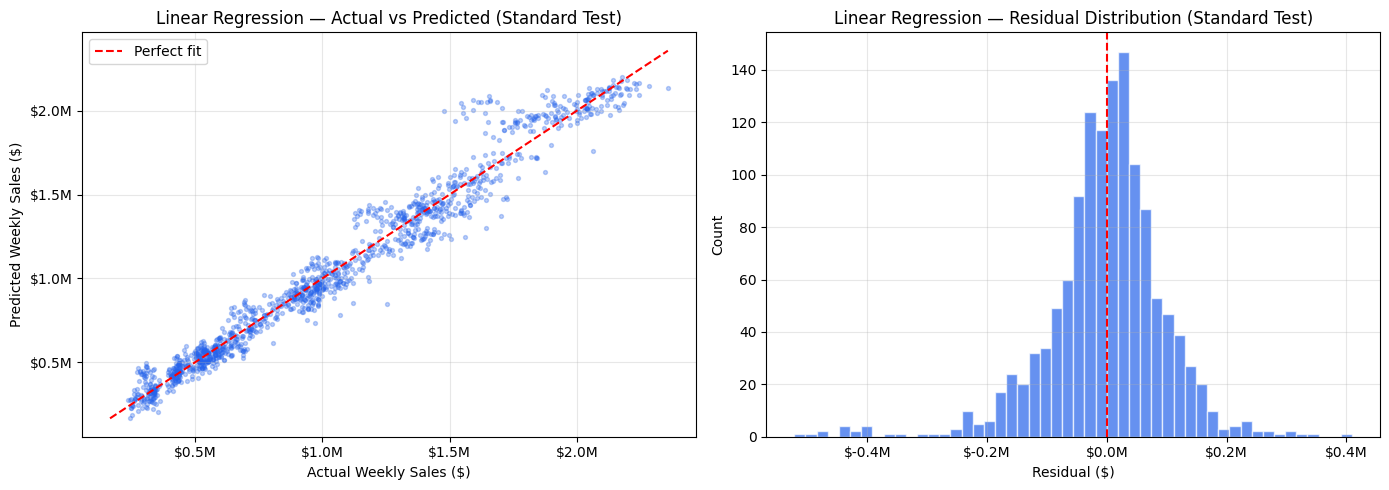

In [15]:
# Plot actual vs predicted scatter and residual distribution for best model
best_preds = predictions['Standard'][best_key]
actuals = test_std[TARGET].values
residuals = actuals - best_preds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
min_val = min(actuals.min(), best_preds.min())
max_val = max(actuals.max(), best_preds.max())
ax1.scatter(actuals, best_preds, alpha=0.3, s=8, color='#2563EB')
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect fit')
ax1.set_xlabel('Actual Weekly Sales ($)')
ax1.set_ylabel('Predicted Weekly Sales ($)')
ax1.set_title(f'{best_name} — Actual vs Predicted (Standard Test)')
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.hist(residuals, bins=50, color='#2563EB', alpha=0.7, edgecolor='white')
ax2.axvline(0, color='red', linestyle='--', linewidth=1.5)
ax2.set_xlabel('Residual ($)')
ax2.set_ylabel('Count')
ax2.set_title(f'{best_name} — Residual Distribution (Standard Test)')
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

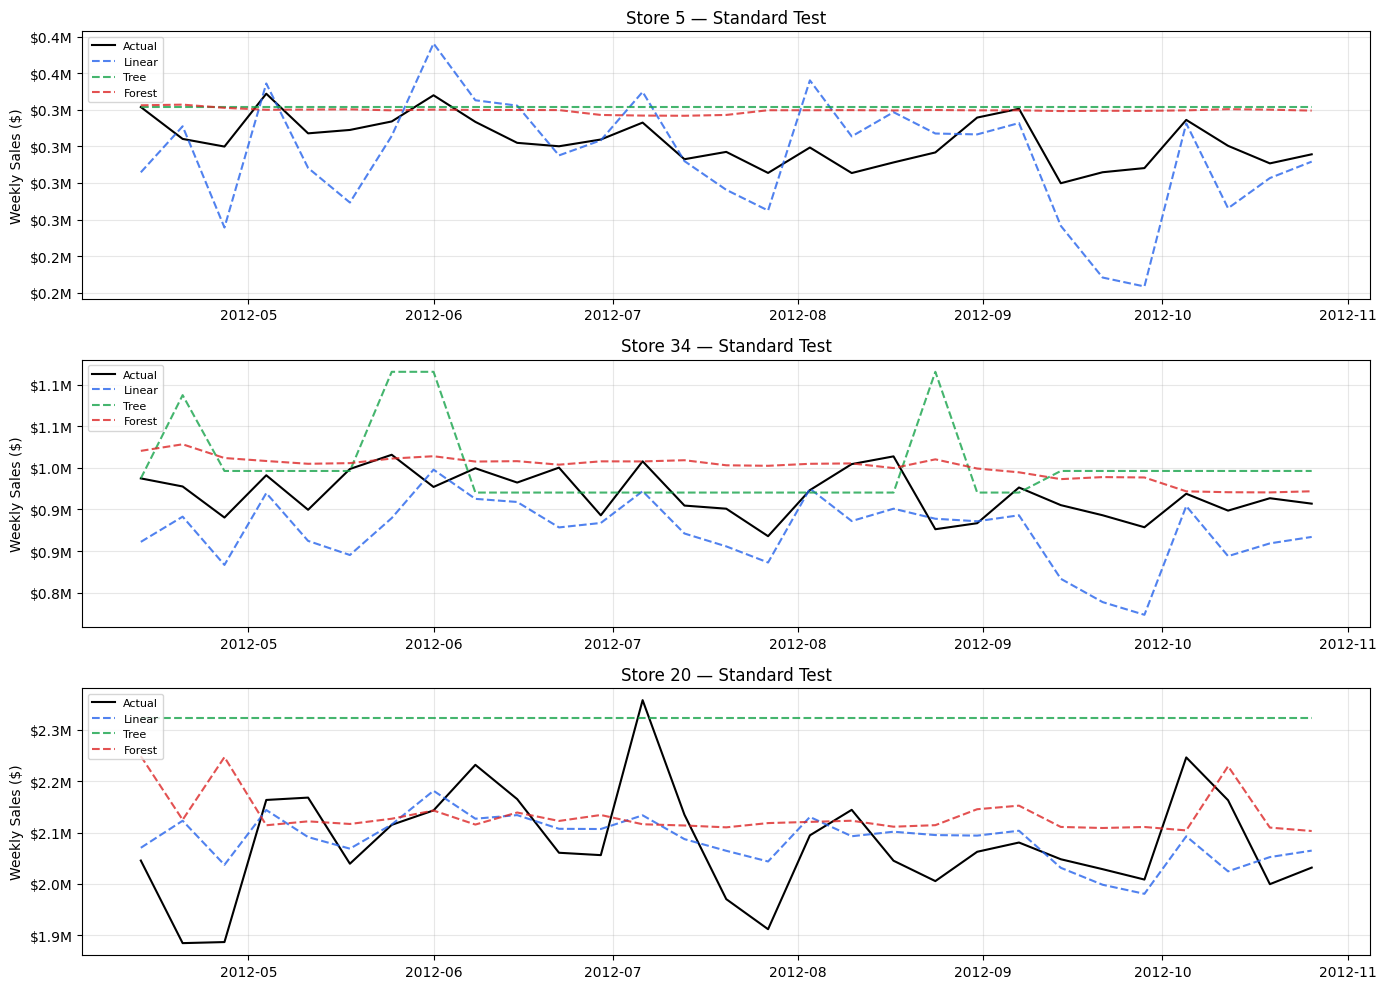

In [16]:
# Plot actual vs predicted sales across representative stores
store_avgs = train_std.groupby('Store')[TARGET].mean().sort_values()
selected_stores = [int(store_avgs.index[2]), int(store_avgs.index[len(store_avgs)//2]), int(store_avgs.index[-1])]

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
for ax, store in zip(axes, selected_stores):
    mask = test_std['Store'] == store
    dates = test_std.loc[mask, 'Date'].values
    ax.plot(dates, test_std.loc[mask, TARGET].values, 'k-', label='Actual', linewidth=1.5)
    ax.plot(dates, predictions['Standard']['linear'][mask], '--', label='Linear', color='#2563EB', alpha=0.8)
    ax.plot(dates, predictions['Standard']['tree'][mask], '--', label='Tree', color='#16A34A', alpha=0.8)
    ax.plot(dates, predictions['Standard']['forest'][mask], '--', label='Forest', color='#DC2626', alpha=0.8)
    ax.set_title(f'Store {store} — Standard Test')
    ax.set_ylabel('Weekly Sales ($)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 9 Feature Importance

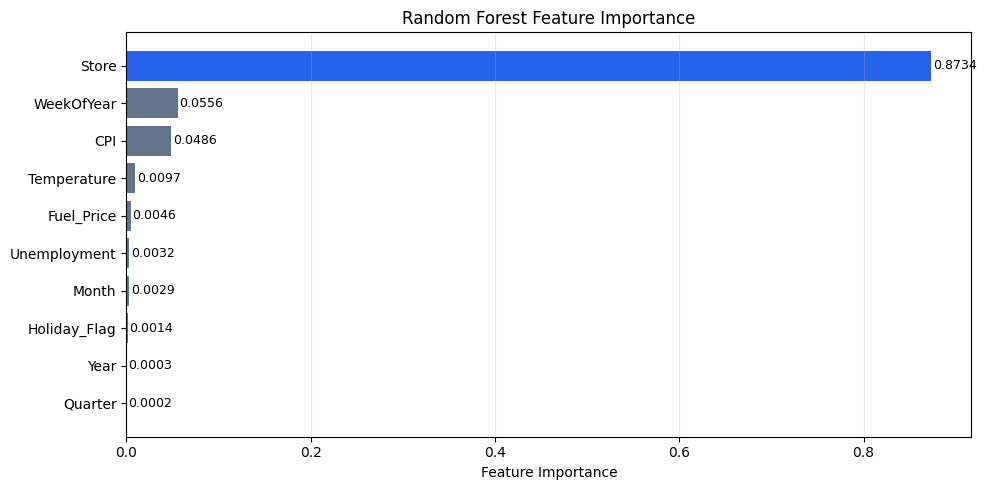

In [17]:
# Compute and plot Random Forest feature importances
forest_pipe = fitted_models['Standard']['forest']
ohe = forest_pipe.named_steps['preprocessor'].named_transformers_['cat']
store_feat_names = [f"Store_{int(c)}" for c in ohe.categories_[0]]
num_feat_names = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
all_feat_names = store_feat_names + num_feat_names

rf_importances = forest_pipe.named_steps['model'].feature_importances_
agg_imp = {'Store': sum(imp for name, imp in zip(all_feat_names, rf_importances) if name.startswith('Store_'))}
for name, imp in zip(all_feat_names, rf_importances):
    if not name.startswith('Store_'):
        agg_imp[name] = float(imp)

sorted_imp = sorted(agg_imp.items(), key=lambda x: x[1], reverse=True)
labels = [k for k, v in sorted_imp]
vals = [v for k, v in sorted_imp]

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2563EB' if f == 'Store' else '#64748B' for f in labels]
bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1])
ax.set_xlabel('Feature Importance')
ax.set_title('Random Forest Feature Importance')
for bar, val in zip(bars, vals[::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontsize=9)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# 10 Save Model

In [18]:
# Refit best model on full dataset and save model.joblib and results.json for app
os.makedirs('app', exist_ok=True)

final_pipe = make_pipeline(best_key)
final_pipe.fit(df[FEATURE_COLS], df[TARGET])
joblib.dump(final_pipe, 'app/model.joblib')

dfs_to_save = []
for eval_name, tr, te in [('Standard', train_std, test_std), ('Holiday-season', train_hol, test_hol)]:
    tmp = te[['Store', 'Date', TARGET]].copy().rename(columns={TARGET: 'Actual'})
    tmp['Date'] = tmp['Date'].dt.strftime('%Y-%m-%d')
    tmp['Evaluation'] = eval_name
    tmp['Linear'] = predictions[eval_name]['linear']
    tmp['Tree']   = predictions[eval_name]['tree']
    tmp['Forest'] = predictions[eval_name]['forest']
    dfs_to_save.append(tmp)

pred_df = pd.concat(dfs_to_save, ignore_index=True)

results_payload = {
    'metrics': all_metrics,
    'best_model': best_name,
    'feature_importance': [{'feature': k, 'importance': round(float(v), 4)} for k, v in sorted_imp],
    'predictions': pred_df.to_dict(orient='records')
}

with open('app/results.json', 'w') as f:
    json.dump(results_payload, f, indent=2)

print("Saved app/model.joblib and app/results.json successfully.")

Saved app/model.joblib and app/results.json successfully.
